<center><img src="logo_cesi_etudiant.png" alt="Description de l'image" style="width: 300px;" /></center>


<center><font size="300">LIVRABLE 1 - CLASSIFICATION BINAIRE </font></center>


Membres du groupe : 

**-** Schadrac APOUPOH 

**-** Daryl BOULOU

**-** William PANCHA 

**-** Jaad CHOKR

# 1. Contexte métier et problématique

## 1.1 Contexte

TouNum est une entreprise spécialisée dans la numérisation de documents, notamment à partir de supports papier. Dans le cadre de l'augmentation du volume de documents numérisés, l'entreprise souhaite développer de nouveaux services reposant sur les techniques de Machine Learning.

L'un des objectifs du projet consiste à mettre en place une chaîne automatisée permettant d'analyser des images et, à terme, de générer automatiquement une légende descriptive de leur contenu.

Avant de réaliser cette étape de génération de légendes (*image captioning*), une étape de filtrage est nécessaire. En effet, l'ensemble des images numérisées par TouNum ne correspond pas nécessairement à des photographies. Le dataset peut également contenir des schémas, des graphiques, des textes scannés, des dessins ou encore des peintures.

L'objectif de ce premier livrable est donc de développer un modèle de classification capable de distinguer automatiquement :

* les **photographies** ;
* les **autres types d'images**.

Cette classification permettra de sélectionner automatiquement les photographies qui pourront ensuite être transmises aux étapes suivantes du workflow.

## 1.2 Problématique

La problématique étudiée dans ce livrable est donc la suivante :

**Comment développer un modèle de réseau de neurones capable de distinguer automatiquement une photographie d'une autre catégorie d'image dans un ensemble de documents numérisés ?**

La difficulté du problème dépend notamment de la nature des images à distinguer. Les textes scannés ou les schémas présentent généralement des caractéristiques visuelles très différentes des photographies. À l'inverse, certaines peintures possèdent un rendu très réaliste et peuvent donc être visuellement proches d'une photographie.

L'objectif sera ainsi de construire progressivement un modèle, d'évaluer ses performances et d'analyser ses limites afin de déterminer s'il est suffisamment pertinent pour être intégré au workflow de TouNum.


# 2. Objectif de la classification

Le problème traité ici est une classification supervisée binaire. Le dataset contient cinq catégories :

| Classe | Signification |
|---|---|
| Painting | Peinture ou illustration |
| Photo | Photographie |
| Schematics | Schéma ou représentation technique |
| Sketch | Dessin ou esquisse |
| Text | Image principalement composée de texte |

Pour notre approche, le modèle apprend d'abord à distinguer les cinq classes en estimant leurs probabilités respectives. Ensuite, la décision binaire repose sur un seuil critique appliqué à la probabilité de la classe `Photo` : si $P(\text{Photo}) \ge \theta$, l'image est retenue comme photographie pour l'étape de génération de légendes ; si $P(\text{Photo}) < \theta$, elle est automatiquement regroupée dans la catégorie `Non-photo` (englobant *Painting*, *Schematics*, *Sketch* et *Text*) et écartée du pipeline. Ce seuil permet d'ajuster le compromis entre la capture maximale des vraies photos et l'exclusion stricte des contenus non photographiques indésirables.

## 3. Importation des librairies

Cette section importe les bibliothèques utilisées pour le chargement des images, la construction du réseau, l'entraînement et la visualisation : pathlib et os pour les chemins, numpy pour les opérations numériques, matplotlib pour les graphiques, Keras pour le réseau et TensorFlow pour le pipeline tf.data. La bibliothèque torch.cuda est utilisée uniquement pour vérifier la disponibilité du GPU.

In [1]:
import os
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pathlib

Dans cet environnement Windows, Keras est configuré avec PyTorch comme backend. Ce choix permet d'utiliser le GPU disponible pour les opérations du modèle. TensorFlow reste utilisé pour le décodage des images et la préparation des datasets.

In [2]:
os.environ['KERAS_BACKEND'] = 'torch'
import keras
from keras import layers
from keras.utils import plot_model
import tensorflow as tf

In [3]:
print("Active backend:", keras.backend.backend())

Active backend: torch


In [4]:
import torch.cuda as cuda

print(cuda.is_available())
if cuda.is_available():
    print(cuda.get_device_name(0))

True
NVIDIA GeForce RTX 4050 Laptop GPU


## 4. Exploration et visualisation des données du dataset

Avant l'entraînement, nous vérifions l'intégrité des fichiers, la répartition des classes et l'aspect visuel des images. Ces contrôles permettent d'éviter qu'un fichier corrompu interrompe un batch et d'identifier un éventuel déséquilibre qui pourrait rendre l'accuracy globale trompeuse.

### 4.1 Vérification des fichiers du datasets

Chaque fichier est lu puis décodé avec TensorFlow. Les fichiers impossibles à décoder sont enregistrés dans invalid_files et affichés. Ils sont ensuite retirés par la cellule suivante afin de ne pas interrompre le chargement du dataset.

Cette suppression est destructive. Dans un contexte de production, il serait préférable de déplacer les fichiers invalides dans un dossier de quarantaine et de conserver un rapport de nettoyage.

In [21]:
datasets_dir = pathlib.Path('datasets')

In [ ]:
invalid_files = []

for file_path in datasets_dir.rglob("*"):
    if file_path.is_file():
        try:
            content = tf.io.read_file(str(file_path))
            _ = tf.io.decode_image(content, expand_animations=False)
        except tf.errors.InvalidArgumentError as e:
            print(f"Fichier corrompu trouvé : {file_path}")
            print(f"Erreur : {e}\n")
            invalid_files.append((file_path, e))

print(f"{len(invalid_files)} fichier(s) invalide(s)")

for file_path, error in invalid_files:
    print(file_path, "->", error)

for invalid_file in invalid_files:
    invalid_file[0].unlink()

La sortie montre les fichiers qui ne peuvent pas être interprétés comme des images valides. L'erreur provient généralement d'un en-tête incohérent ou d'une image incomplètement écrite. Ces fichiers sont exclus avant l'entraînement. Leur nombre doit être surveillé, car un nettoyage important peut modifier la distribution des classes.

### 4.3 Construction des jeux d'entraînement, validation et test

Après nettoyage, les images sont séparées en trois sous-ensembles :

- entraînement : ajuste les poids du réseau ;
- validation : permet de choisir les hyperparamètres et de détecter le sur-apprentissage ;
- test : reste réservé à l'évaluation finale.

La fonction réserve d'abord 70 pour cent des images à l'entraînement. Les 30 pour cent restantes sont ensuite divisées en deux parties, validation et test. La seed 42 rend la séparation reproductible. Le chargement par batches évite de conserver tout le dataset en mémoire simultanément.

In [23]:
batch_size, img_height, img_width, epochs = 32, 128, 128, 10

In [22]:
def build_datasets(data_dir, batch_size, img_size):
    seed_value = 42

    train_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="training",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    val_and_test_ds = keras.utils.image_dataset_from_directory(
        directory=data_dir,
        validation_split=0.3,
        subset="validation",
        seed=seed_value,
        image_size=img_size,
        batch_size=batch_size,
    )

    num_eval_batches = tf.data.experimental.cardinality(val_and_test_ds).numpy()
    val_batches = num_eval_batches // 2

    val_ds = val_and_test_ds.take(val_batches)
    test_ds = val_and_test_ds.skip(val_batches)

    return train_ds, val_ds, test_ds

train_ds, val_ds, test_ds = build_datasets(datasets_dir, batch_size=batch_size, img_size=(img_height, img_width))

Found 41398 files belonging to 5 classes.
Using 28979 files for training.
Found 41398 files belonging to 5 classes.
Using 12419 files for validation.


La distribution des classes permet de vérifier l'équilibre du dataset. Les classes Painting, Photo, Schematics et Text contiennent environ 10 000 images, alors que Sketch est nettement moins représentée. Il faudra donc compléter l'accuracy globale par la précision, le rappel, le F1-score et une matrice de confusion par classe. Une bonne accuracy moyenne peut masquer une mauvaise reconnaissance de la classe minoritaire.

In [27]:
labels = train_ds.class_names
num_classes = len(labels)

class_distribution = {
    label: sum(1 for file in (datasets_dir / label).iterdir() if file.is_file())
    for label in labels
}

print(class_distribution)

{'Painting': 9999, 'Photo': 9993, 'Schematics': 10000, 'Sketch': 1406, 'Text': 10000}


Visualisons quelques images du jeu d'entraînement

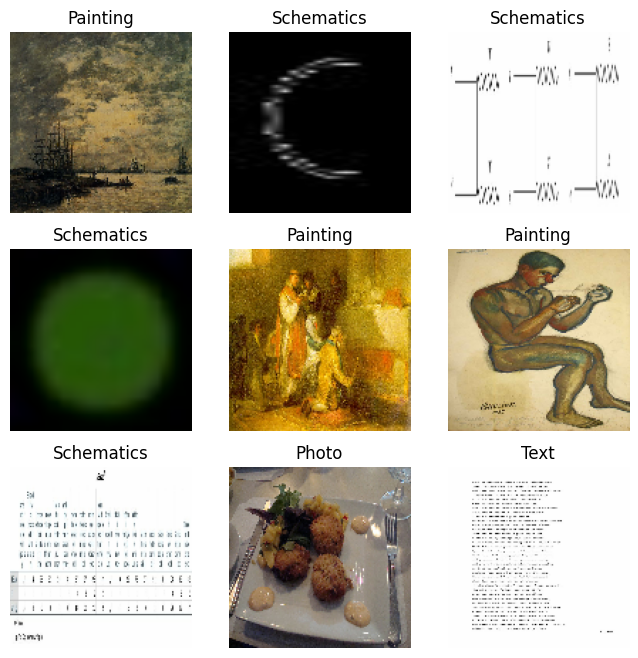

In [109]:
plt.figure(figsize=(8, 8))
for images, label in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i +1)
        ax.imshow(images[i].numpy().astype('uint8'))
        plt.title(labels[label[i]])
        plt.axis("off")

### 4.4 Chargement des jeux d'entraînement dans le cache

Pour accélérer les époques successives, le pipeline utilise cache, shuffle et prefetch. Cache() évite de relire et décoder les mêmes fichiers à chaque époque ce en chargeant toutes les données directement dans la RAM.

Les images sont converties en uint8, soit un octet par canal, au lieu de float32, soit quatre octets par canal. Pour une image RGB de 128 par 128 pixels, la représentation brute passe ainsi d'environ 196 Ko à 49 Ko. Le cache occupe donc moins de mémoire.

Cette conversion ne supprime pas l'information utile : la couche Rescaling 1/255 du réseau reconvertit les pixels en valeurs réelles normalisées entre 0 et 1 avant les convolutions.

In [24]:
def cast_to_uint8(images, labels):
    images = tf.cast(images, tf.uint8)
    return images, labels

In [25]:
AUTOTUNE = tf.data.experimental.AUTOTUNE

train_data = train_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)
test_data = test_ds.map(cast_to_uint8, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(buffer_size=AUTOTUNE)

In [26]:
import psutil
from tqdm import tqdm

process = psutil.Process(os.getpid())

def preload_and_cache(dataset, total_batches, split_name="Dataset"):
    initial_ram = process.memory_info().rss / (1024 ** 2)
    print(f"\n--- Caching {split_name} (RAM before: {initial_ram:.1f} MB) ---")
    
    for _ in tqdm(dataset, total=total_batches, desc=f"Loading {split_name}", unit="batch"):
        pass

    final_ram = process.memory_info().rss / (1024 ** 2)
    delta_ram = final_ram - initial_ram
    print(f"{split_name} cached. RAM used: {final_ram:.1f} MB (+{delta_ram:.1f} MB added)")

preload_and_cache(train_data, len(train_ds), "Train")
preload_and_cache(val_data, len(val_ds), "Validation")
preload_and_cache(test_data, len(test_ds), "Test")


--- Caching Train (RAM before: 1128.3 MB) ---


Loading Train: 100%|██████████| 114/114 [01:00<00:00,  1.88batch/s]


Train cached. RAM used: 3019.9 MB (+1891.5 MB added)

--- Caching Validation (RAM before: 3019.9 MB) ---


Loading Validation: 100%|██████████| 24/24 [00:13<00:00,  1.82batch/s]


Validation cached. RAM used: 3659.6 MB (+639.7 MB added)

--- Caching Test (RAM before: 3659.6 MB) ---


Loading Test: 100%|██████████| 25/25 [00:09<00:00,  2.62batch/s]

Test cached. RAM used: 4071.1 MB (+411.5 MB added)


## 5. Construction du modèle CNN

Un CNN est adapté aux images car ses filtres convolutifs exploitent la proximité spatiale des pixels. Les premières convolutions apprennent des contours et des textures ; les suivantes combinent ces motifs pour représenter des formes plus complexes.

- Rescaling normalise les pixels dans l'intervalle 0, 1 ;
- Conv2D extrait des caractéristiques locales ;
- MaxPooling2D réduit la résolution tout en conservant les activations dominantes ;
- Flatten transforme les cartes de caractéristiques en vecteur ;
- Dense combine ces caractéristiques ;
- la sortie softmax renvoie une probabilité pour chacune des cinq classes.

Le baseline est volontairement simple. Il sert de référence pour mesurer l'effet des réglages et des techniques de régularisation testés ensuite.

### Architecture détaillée du baseline

Le réseau suit l'architecture suivante: #TOADD

In [9]:
model_baseline = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

model_baseline.summary()

model_baseline.compile(optimizer="adam", loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
history_baseline = model_baseline.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
)

Epoch 1/10
  1/869 ━━━━━━━━━━━━━━━━━━━━ 44s 51ms/step - accuracy: 0.0938 - loss: 1.6268

c:\Users\brago\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


869/869 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.7797 - loss: 0.5148 - val_accuracy: 0.8505 - val_loss: 0.3768
Epoch 2/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.8690 - loss: 0.3320 - val_accuracy: 0.8683 - val_loss: 0.3278
Epoch 3/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.8969 - loss: 0.2624 - val_accuracy: 0.8449 - val_loss: 0.3713
Epoch 4/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.9200 - loss: 0.2069 - val_accuracy: 0.8824 - val_loss: 0.3034
Epoch 5/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 23s 27ms/step - accuracy: 0.9391 - loss: 0.1626 - val_accuracy: 0.8952 - val_loss: 0.3043
Epoch 6/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9569 - loss: 0.1160 - val_accuracy: 0.8804 - val_loss: 0.3959
Epoch 7/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.9707 - loss: 0.0805 - val_accuracy: 0.8810 - val_loss: 0.4613
Epoch 8/10
869/869 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.9769 - loss: 0.0656 - val_accurac

In [28]:
model_baseline.save('model_baseline.weights.h5')

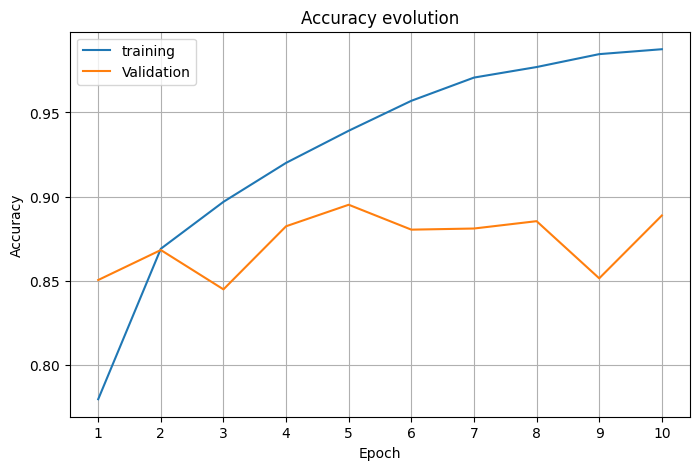

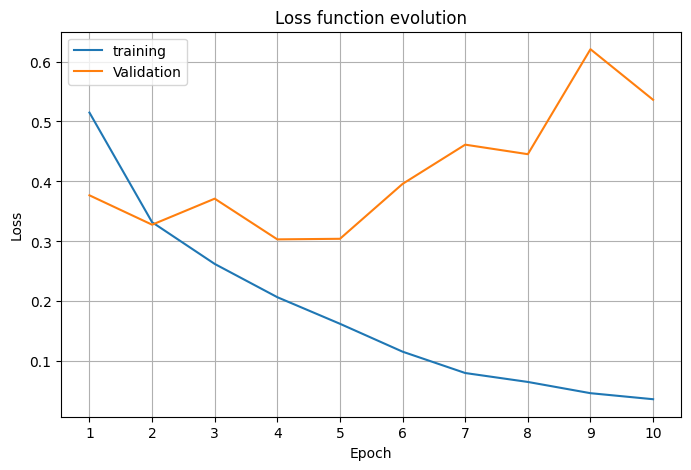

In [18]:
acc = history_baseline.history["accuracy"]
val_acc = history_baseline.history["val_accuracy"]
loss = history_baseline.history["loss"]
val_loss = history_baseline.history["val_loss"]
actual_epochs = range(1, epochs + 1)

# accuracy plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, acc, label="training")
plt.plot(actual_epochs, val_acc, label="Validation")
plt.title("Accuracy evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# loss plots
plt.figure(figsize=(8, 5))
plt.plot(actual_epochs, loss, label="training")
plt.plot(actual_epochs, val_loss, label="Validation")
plt.title("Loss function evolution")
plt.xticks(actual_epochs)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')

final training loss: 0.03674371540546417
final validation loss: 0.5361804962158203
--- generalization gap: 0.49943678081035614 ---

final training accuracy: 0.9875125885009766
final validation accuracy: 0.8887768983840942
--- accuracy gap: 0.09873569011688232 ---


Le baseline présente un écart important entre les performances d'entraînement et de validation `~0.5`. Cette erreur prouve que le modèle est en sur-apprentissage : le réseau apprend des particularités des images vues, mais ces représentations se transfèrent moins bien aux images non vues.

L'objectif des essais suivants est de réduire cet écart, et non simplement d'augmenter l'accuracy d'entraînement.

## 6. Expériences menées pour remédier au problème de surapprentissage

Nous avons mené différentes expériences portant sur le réglage des hyperparamètres et sur plusieurs techniques de régularisation. L'objectif était de réduire l'écart entre les performances d'entraînement et de validation, tout en conservant une bonne capacité d'apprentissage.

- **Influence de la taille du batch**<br>

Nous avons testé différentes valeurs de batch size: `[16,32,64,128,256]` et entraîné le modèle sur 5 époques. La meilleure valeur observée est `256`. Elle est celle qui a permis d'obtenir la plus petite erreur de généralisation.

- **Influence de la taille des images**<br>

Nous avons comparé plusieurs résolutions d'entrée: `[128x128, 160x160, 192x192, 224x224, 255x255]`. La taille retenue est **128 × 128 pixels** car elle est celle qui permet d'obtenir la plus petite valeur d'erreur de validation.

- **Influence du taux d'apprentissage**<br>

Nous avons testé plusieurs valeurs du taux d'apprentissage avec des valeurs comprises entre `[1e-5; 1e-1]`. La valeur retenue est approximativement `2.5234725706127004e-04`. Elle permet au modèle de converger vers la meilleure valeur d'erreur de validation.

- **Data augmentation**<br>

Etant donné que le dataset est en déficit de données de la classe **Sketch**. Nous avons essayé du data augmentation sur cette dernière pour réquilibrer les classes. Cependant nous n'avons pas observé de différence importante sur la perte de validation avec les transformations testées. Dans le cadre de cette expérimentation, la data augmentation n'a donc pas apporté d'amélioration suffisamment nette pour être retenue comme élément permettant de réduire le surapprentissage.

- **Dropout**<br>

Comme pour la data augmentation, l'ajout de dropout n'a pas produit de différence significative sur la perte de validation dans les configurations testées. Il n'a lui aussi pas été retenu pour réduire le surapprentissage

- **Régularisation Elastic Net**<br>

Elle combine une pénalité L1 et une pénalité L2 afin de limiter la complexité du modèle. Elle a été appliqué à la fois sur la dernière couche de convolution et sur la première couche dense. Elle a produit de résultats significatifs car elle a permis d'obtenir une erreur de généralisation de ` ~0.06`

- **Early stopping**<br>

L'early stopping sera appliqué au modèle final. Le principe consiste à surveiller la perte de validation et à arrêter l'entraînement lorsqu'elle ne s'améliore plus pendant un nombre défini d'époques. Avec restore_best_weights=True, les poids correspondant à la meilleure époque de validation sont restaurés et pourront être sauvegardés. Cette méthode permet de choisir l'époque optimale sans retenir automatiquement la dernière époque d'entraînement.

En résumé, les réglages retenus avant la construction du modèle final sont un batch size de `256`, une résolution d'image `128 × 128` et un learning rate proche de `2.5234725706127004e-04`. L'Elastic Net apparaît comme la technique de régularisation la plus prometteuse dans les essais réalisés, tandis que les effets de la data augmentation et du dropout sont restés limités. La comparaison finale sur le jeu de test permettra de vérifier que l'amélioration observée correspond bien à une meilleure généralisation et non uniquement à une évolution favorable des courbes de validation.

Ci-joint le graphique montrant toutes les courbes d'erreur pour chacune des expériences

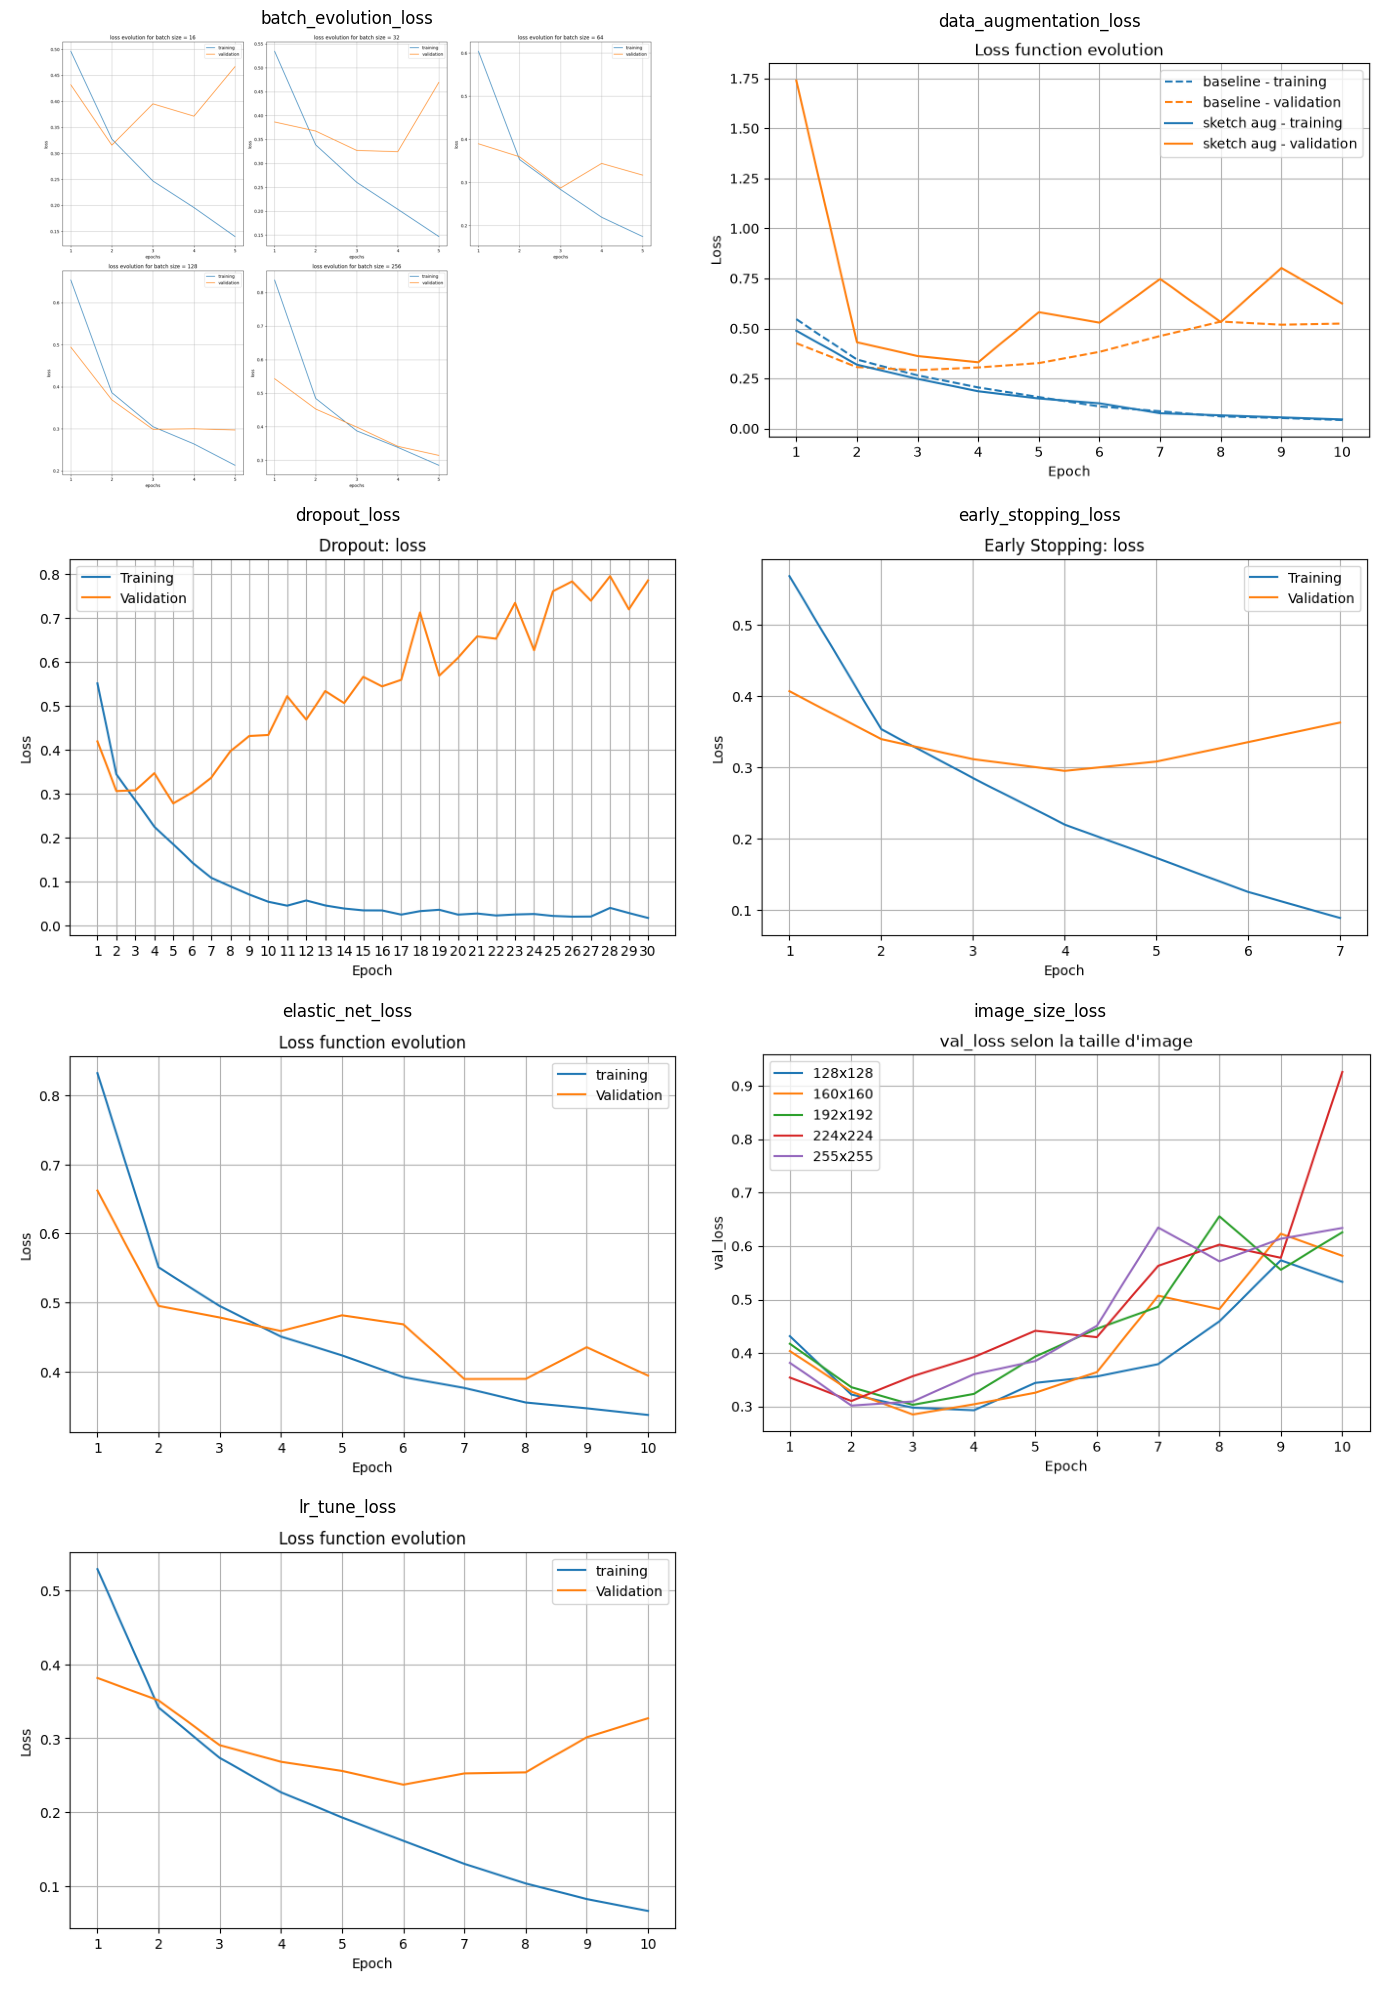

In [1]:
import math
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

folder = Path("plots_livrable")
images = sorted(folder.glob("*.png"))

n = len(images)
cols = 2
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axes = axes.flatten()

for i, img_path in enumerate(images):
    img = mpimg.imread(str(img_path))
    axes[i].imshow(img)
    axes[i].set_title(img_path.stem)
    axes[i].axis("off")

# Masquer les axes vides restants
for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 7. Construction du modèle final et résultats

Ici nous allons utiliser toutes les valeurs et techniques de régularisation efficaces qu'on a pu observer grâce aux expériences

In [7]:
best_lr, batch_size, img_height, img_width, epochs = 0.00025234725706127004, 256, 128, 128, 30

In [42]:
def plot_loss(model_history):
    acc = model_history.history["accuracy"]
    val_acc = model_history.history["val_accuracy"]
    loss = model_history.history["loss"]
    val_loss = model_history.history["val_loss"]
    actual_epochs = range(1, len(loss) + 1)

    # accuracy plots
    plt.figure(figsize=(8, 5))
    plt.plot(actual_epochs, acc, label="training")
    plt.plot(actual_epochs, val_acc, label="Validation")
    plt.title("Accuracy evolution")
    plt.xticks(actual_epochs)
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.show()

    # loss plots
    plt.figure(figsize=(8, 5))
    plt.plot(actual_epochs, loss, label="training")
    plt.plot(actual_epochs, val_loss, label="Validation")
    plt.title("Loss function evolution")
    plt.xticks(actual_epochs)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f'final training loss: {loss[-1]}\nfinal validation loss: {val_loss[-1]}')
    print(f'--- generalization gap: {abs(loss[-1] - val_loss[-1])} ---')
    print(f'\nfinal training accuracy: {acc[-1]}\nfinal validation accuracy: {val_acc[-1]}')
    print(f'--- accuracy gap: {abs(acc[-1] - val_acc[-1])} ---')
    best_index_es = val_loss.index(min(val_loss))
    print(f"Meilleure époque Early Stopping : {best_index_es + 1}")
    print(f"Validation loss minimale : {val_loss[best_index_es]}")
    print(f"Validation accuracy à cette époque : {val_acc[best_index_es]}")

In [8]:
elastic_dense = keras.regularizers.L1L2(l1=1e-4, l2=1e-4)
elastic_conv = keras.regularizers.L1L2(l1=1e-5, l2=1e-5)

In [ ]:
model_full = keras.Sequential([

    layers.Input(shape=(img_height, img_width, 3)),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu", kernel_regularizer=elastic_conv),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_regularizer=elastic_dense),
    layers.Dense(num_classes, activation="softmax")
])

model_full.summary()

model_full.compile(optimizer=keras.optimizers.Adam(learning_rate=best_lr), loss ='sparse_categorical_crossentropy', metrics=['accuracy'])

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

L'architecture finale du modèle est ci-dessous

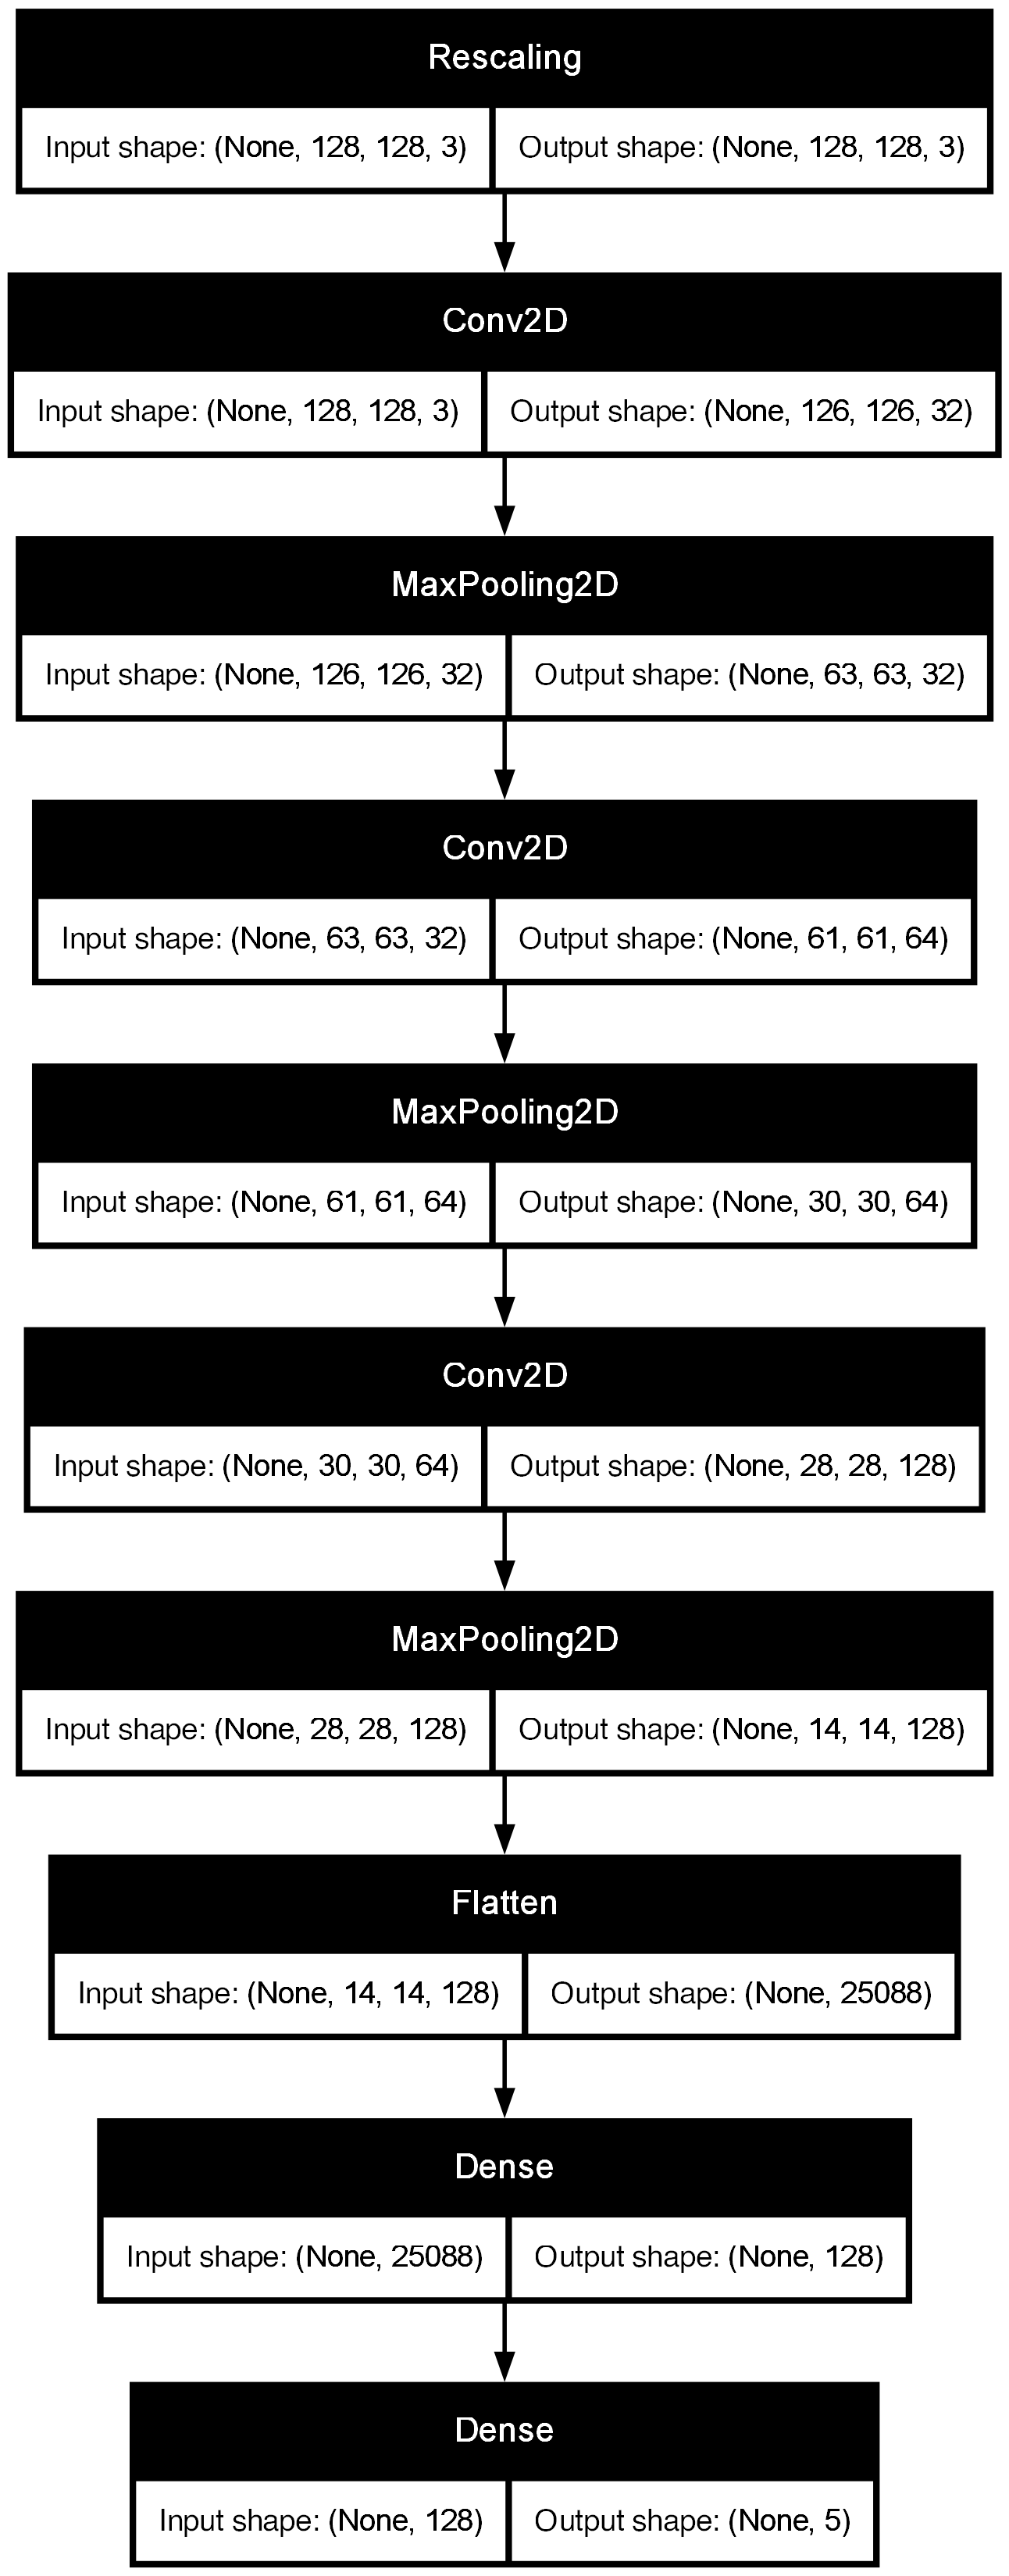

In [18]:
plot_model(model_full, to_file='final_model.png', show_shapes=True)

In [ ]:
early_stopping_callback = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
)

history_full = model_full.fit(
    train_data,
    validation_data=val_data,
    epochs=epochs,
    batch_size=batch_size,
    callbacks=[early_stopping_callback]
)

Epoch 1/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 29s 32ms/step - accuracy: 0.7361 - loss: 0.9979 - val_accuracy: 0.7792 - val_loss: 0.6930
Epoch 2/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 28s 31ms/step - accuracy: 0.8051 - loss: 0.6076 - val_accuracy: 0.8307 - val_loss: 0.5511
Epoch 3/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.8383 - loss: 0.5228 - val_accuracy: 0.8570 - val_loss: 0.4752
Epoch 4/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 29ms/step - accuracy: 0.8603 - loss: 0.4686 - val_accuracy: 0.8687 - val_loss: 0.4550
Epoch 5/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 27s 30ms/step - accuracy: 0.8755 - loss: 0.4254 - val_accuracy: 0.8871 - val_loss: 0.4023
Epoch 6/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 26s 29ms/step - accuracy: 0.8819 - loss: 0.4067 - val_accuracy: 0.8716 - val_loss: 0.4215
Epoch 7/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 30s 34ms/step - accuracy: 0.8906 - loss: 0.3847 - val_accuracy: 0.8911 - val_loss: 0.3874
Epoch 8/30
906/906 ━━━━━━━━━━━━━━━━━━━━ 46s 51ms/step - accuracy: 0.8958 - loss: 0.3681 - 

In [48]:
model_full.save('model_full.weights.h5')

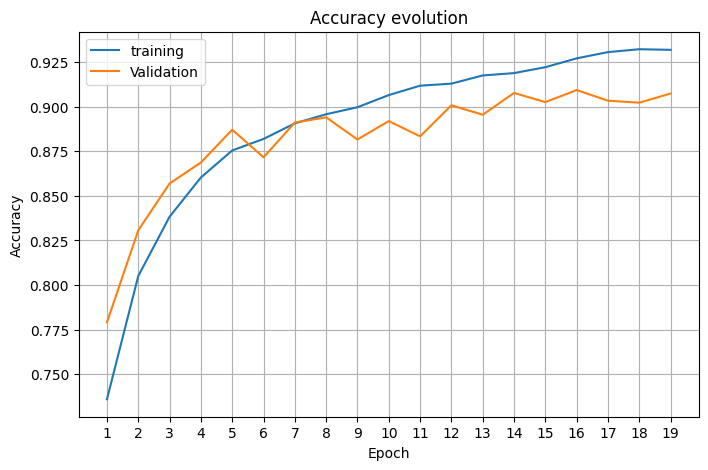

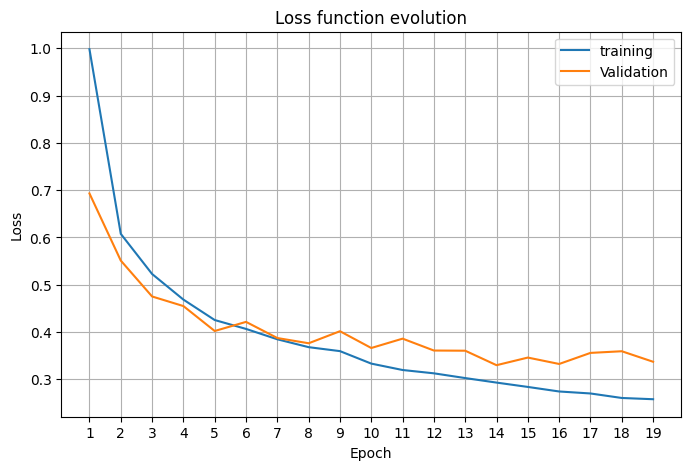

final training loss: 0.2580512762069702
final validation loss: 0.3372468948364258
--- generalization gap: 0.07919561862945557 ---

final training accuracy: 0.9318472146987915
final validation accuracy: 0.9073776006698608
--- accuracy gap: 0.024469614028930664 ---
Meilleure époque Early Stopping : 14
Validation loss minimale : 0.32999199628829956
Validation accuracy à cette époque : 0.9076997637748718


In [47]:
plot_loss(history_full)

### 7.1 Après entraînement

Après entraînement et en utilisant early stopping, comme présenté plus haut nous pouvons constater que la meilleure époque est `14` et que le modèle final nous permet d'obtenir:
- une erreur d'entraînement de `~0.26`
- une erreur de généralisation de `~0.08`

###  7.2 Résultats

In [ ]:
from sklearn.metrics import (classification_report, confusion_matrix, precision_score, recall_score, f1_score, roc_curve, roc_auc_score)

In [ ]:
print("--- Évaluation métier : Photo contre Non-photo ---")
test_loss, test_accuracy_multiclass = model_full.evaluate(test_data, verbose=0)
print(f"Test loss multiclasses : {test_loss:.4f}")
print(f"Accuracy multiclasses  : {test_accuracy_multiclass * 100:.2f}%")

print("\nGénération des prédictions...")
y_true_multiclass = np.concatenate([y.numpy() for _, y in test_data], axis=0)
y_pred_probs = model_full.predict(test_data, verbose=0)
y_pred_multiclass = np.argmax(y_pred_probs, axis=1)

photo_index = labels.index("Photo")
y_true_binary = (y_true_multiclass == photo_index).astype(int)
y_pred_binary = (y_pred_multiclass == photo_index).astype(int)
photo_probability = y_pred_probs[:, photo_index]

print("\n--- Rapport binaire Photo / Non-photo ---")
print(classification_report(
    y_true_binary,
    y_pred_binary,
    target_names=["Non-photo", "Photo"],
    digits=4
))

binary_precision = precision_score(y_true_binary, y_pred_binary, zero_division=0)
binary_recall = recall_score(y_true_binary, y_pred_binary, zero_division=0)
binary_f1 = f1_score(y_true_binary, y_pred_binary, zero_division=0)
binary_accuracy = (y_true_binary == y_pred_binary).mean()
binary_auc = roc_auc_score(y_true_binary, photo_probability)

print(f"Accuracy Photo / Non-photo : {binary_accuracy * 100:.2f}%")
print(f"Précision Photo            : {binary_precision * 100:.2f}%")
print(f"Rappel Photo               : {binary_recall * 100:.2f}%")
print(f"F1-score Photo             : {binary_f1 * 100:.2f}%")
print(f"AUC-ROC                    : {binary_auc:.4f}")

--- Évaluation métier : Photo contre Non-photo ---
Test loss multiclasses : 0.3331
Accuracy multiclasses  : 90.80%

Génération des prédictions...

--- Rapport binaire Photo / Non-photo ---
              precision    recall  f1-score   support

   Non-photo     0.9528    0.9554    0.9541      4756
       Photo     0.8592    0.8519    0.8555      1519

    accuracy                         0.9304      6275
   macro avg     0.9060    0.9037    0.9048      6275
weighted avg     0.9302    0.9304    0.9303      6275

Accuracy Photo / Non-photo : 93.04%
Précision Photo            : 85.92%
Rappel Photo               : 85.19%
F1-score Photo             : 85.55%
AUC-ROC                    : 0.9758


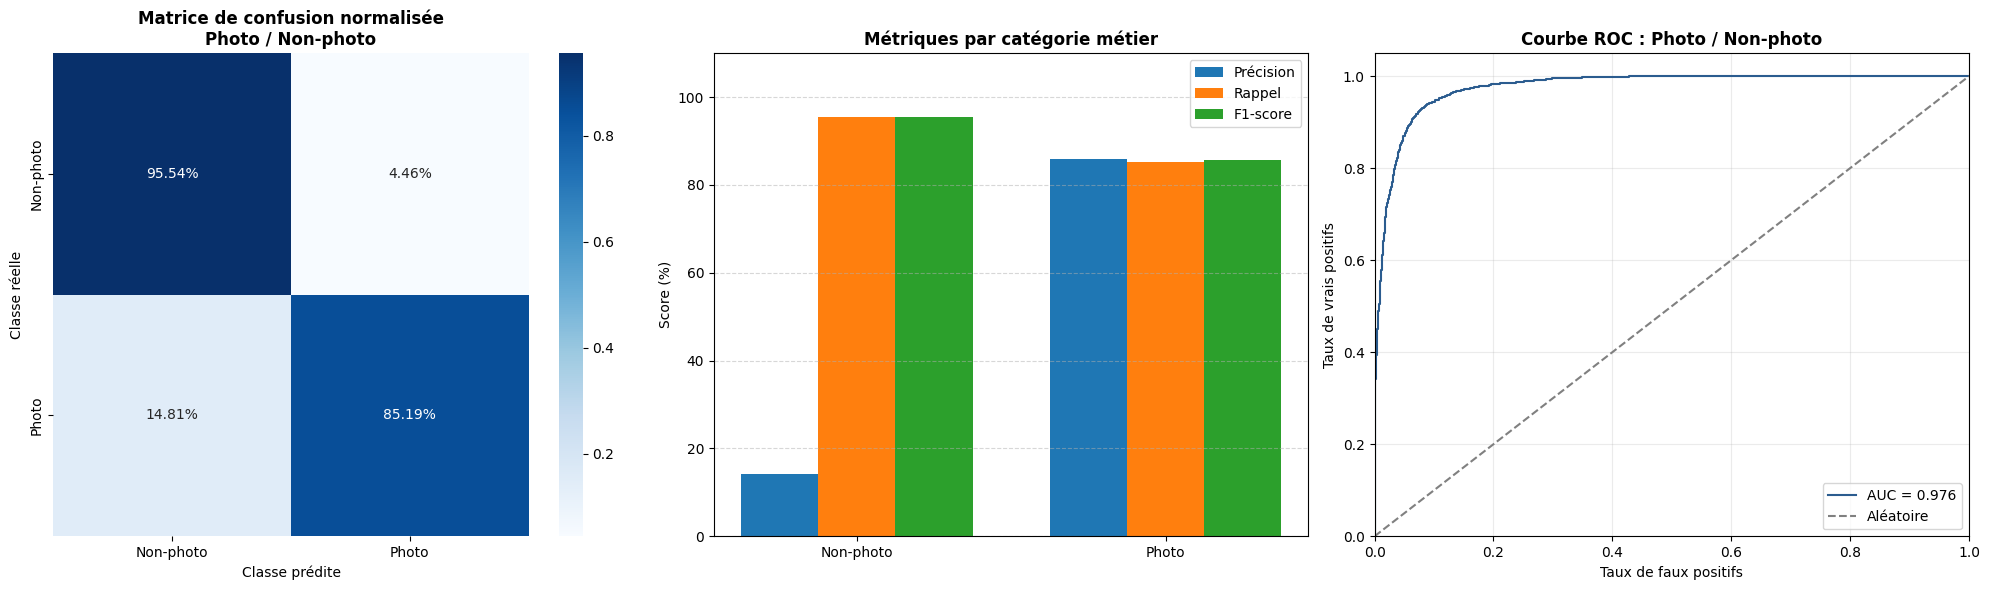

In [29]:
import seaborn as sns

binary_cm = confusion_matrix(y_true_binary, y_pred_binary, normalize="true")
precision_values = [1 - binary_precision, binary_precision]
recall_values = [recall_score(y_true_binary, y_pred_binary, pos_label=0, zero_division=0), binary_recall]
f1_values = [f1_score(y_true_binary, y_pred_binary, pos_label=0, zero_division=0), binary_f1]
roc_fpr, roc_tpr, _ = roc_curve(y_true_binary, photo_probability)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

sns.heatmap(
    binary_cm,
    annot=True,
    fmt=".2%",
    cmap="Blues",
    xticklabels=["Non-photo", "Photo"],
    yticklabels=["Non-photo", "Photo"],
    ax=ax1
)
ax1.set_title("Matrice de confusion normalisée\nPhoto / Non-photo", fontweight="bold")
ax1.set_xlabel("Classe prédite")
ax1.set_ylabel("Classe réelle")

x = np.arange(2)
width = 0.25
ax2.bar(x - width, np.array(precision_values) * 100, width, label="Précision")
ax2.bar(x, np.array(recall_values) * 100, width, label="Rappel")
ax2.bar(x + width, np.array(f1_values) * 100, width, label="F1-score")
ax2.set_title("Métriques par catégorie métier", fontweight="bold")
ax2.set_ylabel("Score (%)")
ax2.set_xticks(x)
ax2.set_xticklabels(["Non-photo", "Photo"])
ax2.set_ylim(0, 110)
ax2.grid(axis="y", linestyle="--", alpha=0.5)
ax2.legend()

ax3.plot(roc_fpr, roc_tpr, label=f"AUC = {binary_auc:.3f}", color="#2b5c8f")
ax3.plot([0, 1], [0, 1], "--", color="grey", label="Aléatoire")
ax3.set_title("Courbe ROC : Photo / Non-photo", fontweight="bold")
ax3.set_xlabel("Taux de faux positifs")
ax3.set_ylabel("Taux de vrais positifs")
ax3.set_xlim(0, 1)
ax3.set_ylim(0, 1.05)
ax3.grid(alpha=0.25)
ax3.legend(loc="lower right")

plt.tight_layout()
plt.show()

### *Interprétation des résultats selon l'objectif métier*

L'objectif opérationnel est de déterminer si une image est une **photographie** ou une **non-photo**. Pour cette analyse, les quatre classes non photographiques — Painting, Schematics, Sketch et Text — sont regroupées dans une seule catégorie appelée **Non-photo**. Le modèle reste entraîné sur les cinq classes d'origine, mais ses prédictions sont converties en deux catégories pour l'évaluation métier.

La conversion est la suivante :

- une prédiction Photo devient la classe positive **Photo** ;
- une prédiction Painting, Schematics, Sketch ou Text devient la classe **Non-photo**.

Cette étape est indispensable : une erreur entre Painting et Schematics n'est pas réellement problématique pour le besoin métier, car ces deux images doivent dans tous les cas être rejetées comme non-photographies. En revanche, une confusion entre Photo et l'une des quatre autres classes constitue une erreur métier.

#### *Lecture de la matrice de confusion*

La matrice de confusion binaire permet d'identifier les quatre situations possibles :

- **Vrai positif** : une photographie correctement reconnue comme Photo ;
- **Faux négatif** : une photographie classée comme Non-photo. Elle est alors rejetée à tort et ne pourra pas être transmise au système de génération de légendes ;
- **Faux positif** : une image non photographique classée comme Photo. Elle est alors transmise à tort au traitement suivant ;
- **Vrai négatif** : une image non photographique correctement reconnue comme Non-photo.

Pour le projet, le rappel de la classe Photo est particulièrement important. Il mesure la proportion de photographies effectivement récupérées par le filtre. Une valeur faible signifie que trop de photographies sont rejetées. La précision de Photo mesure quant à elle la fiabilité des images sélectionnées : une valeur faible signifie que le système transmet trop de non-photographies.

#### *Lecture des métriques*

Le graphique des métriques compare la précision, le rappel et le F1-score pour Photo et Non-photo.

Sur le jeu de test utilisé, le modèle obtient une **accuracy binaire de 93,04 %**. La classe `Non-photo` atteint une précision de **95,28 %**, un rappel de **95,54 %** et un F1-score de **95,41 %**. La classe `Photo` atteint une précision de **85,92 %**, un rappel de **85,19 %** et un F1-score de **85,55 %**. L'AUC-ROC est de **0,9758**, ce qui indique une très bonne capacité globale à classer les photographies au-dessus des non-photographies lorsque le seuil de décision varie.


Le rappel de **85,19 %** pour Photo signifie que la majorité des photographies sont récupérées par le filtre, mais qu'environ **14,81 %** d'entre elles sont encore rejetées comme Non-photo. La précision de **85,92 %** signifie que la majorité des images sélectionnées comme Photo sont réellement des photographies ; les images restantes sont des non-photographies transmises à tort. Ces deux métriques sont plus directement pertinentes pour le besoin métier que l'accuracy multiclasses. 

Ces métriques répondent efficacement à la contrainte métier : le modèle présente un excellent taux de vrais négatifs **(95,54 %)** et maintient ainsi un taux de faux positifs très faible, à seulement **4,46%**. Il limite donc drastiquement le risque de classifier des non-photos en photos, ce qui constitue le cas de figure le plus problématique pour l'usage cible. Ces indicateurs de filtrage sont plus directement pertinents pour le besoin opérationnel que la seule accuracy globale. 

Enfin, afin de déterminer si une image est une photographie ou une non-photographie, nous devons choisir un seuil de décision sur la probabilité prédite pour la classe Photo.<br> Plutôt que d'utiliser arbitrairement le seuil de 0,5, nous retenons **le seuil de Youden**. Celui-ci correspond au point de la courbe ROC qui maximise simultanément le taux de vrais positifs et le taux de vrais négatifs. Il fournit ainsi un compromis équilibré entre le rappel des photographies et le rejet des non-photographies.

In [ ]:
optimal_idx = np.argmax(roc_tpr - roc_fpr)
optimal_threshold = _[optimal_idx]

print(f"Seuil optimal de Youden : {optimal_threshold:.4f}")
print(f"Rappel Photo associé : {roc_tpr[optimal_idx]:.2%}")
print(f"Taux de faux positifs associé : {roc_fpr[optimal_idx]:.2%}")

Seuil optimal (Youden) : 0.2301
Rappel Photo associé : 93.94%
Taux de faux positifs associé : 8.79%


Ainsi à partir du moment où une image a une probabilité de 0.23 pour la classe photo, l'image peut être considérée comme une photo.